In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")

display(df.head())

print("\nDataset Shape:", df.shape)

print("\nColumn Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

display(df.describe(include='all'))


Dataset loaded successfully!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S



Dataset Shape: (891, 12)

Column Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing Values:
PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare     

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
count,891.000000,891.000000,891.000000,891,891,714.000000,891.000000,891.000000,891,891.000000,204,889
unique,NaN,NaN,NaN,891,2,NaN,NaN,NaN,681,NaN,147,3
top,NaN,NaN,NaN,"Braund, Mr. Owen Harris",male,NaN,NaN,NaN,347082,NaN,G6,S
freq,NaN,NaN,NaN,1,577,NaN,NaN,NaN,7,NaN,4,644
mean,446.000000,0.383838,2.308642,NaN,NaN,29.699118,0.523008,0.381594,NaN,32.204208,NaN,NaN
std,257.353842,0.486592,0.836071,NaN,NaN,14.526497,1.102743,0.806057,NaN,49.693429,NaN,NaN
min,1.000000,0.000000,1.000000,NaN,NaN,0.420000,0.000000,0.000000,NaN,0.000000,NaN,NaN
25%,223.500000,0.000000,2.000000,NaN,NaN,20.125000,0.000000,0.000000,NaN,7.910400,NaN,NaN
50%,446.000000,0.000000,3.000000,NaN,NaN,28.000000,0.000000,0.000000,NaN,14.454200,NaN,NaN
75%,668.500000,1.000000,3.000000,NaN,NaN,38.000000,1.000000,0.000000,NaN,31.000000,NaN,NaN


In [2]:

# Create a data quality report

quality_report = pd.DataFrame({
    'Data Type': df.dtypes.astype(str),
    'Missing Values': df.isnull().sum(),
    'Missing Percentage': (
        df.isnull().sum() / len(df) * 100
    ).round(2),
    'Unique Values': df.nunique()
})

display(quality_report)

print("Total Rows:", len(df))
print("Total Columns:", len(df.columns))
print("Duplicate Rows:", df.duplicated().sum())


,Data Type,Missing Values,Missing Percentage,Unique Values
PassengerId,int64,0,0.00,891
Survived,int64,0,0.00,2
Pclass,int64,0,0.00,3
Name,object,0,0.00,891
Sex,object,0,0.00,2
Age,float64,177,19.87,88
SibSp,int64,0,0.00,7
Parch,int64,0,0.00,7
Ticket,object,0,0.00,681
Fare,float64,0,0.00,248


Total Rows: 891
Total Columns: 12
Duplicate Rows: 0


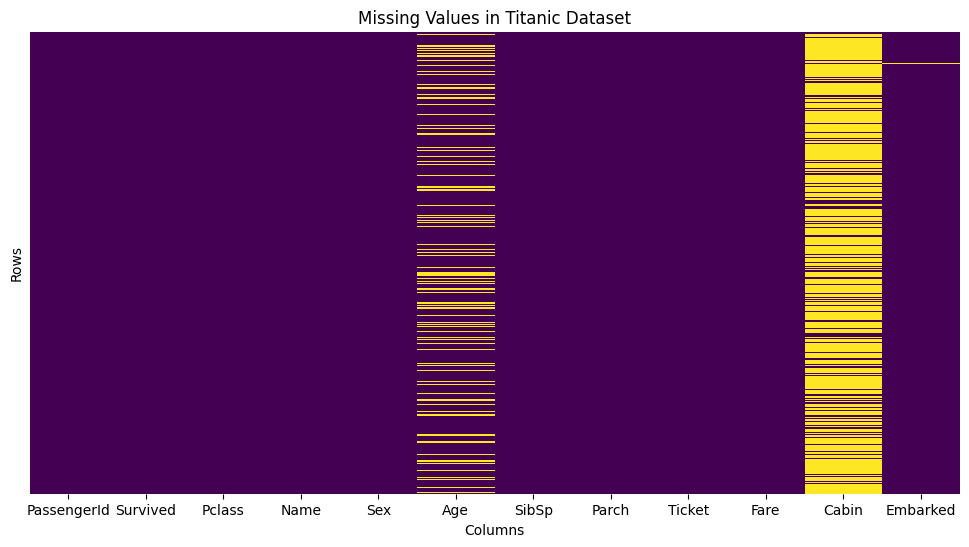

In [3]:

plt.figure(figsize=(12, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    cmap='viridis',
    yticklabels=False
)

plt.title('Missing Values in Titanic Dataset')
plt.xlabel('Columns')
plt.ylabel('Rows')
plt.show()


In [4]:

# Keep an untouched copy for comparison

original_df = df.copy()

print("Original dataset preserved!")
print("Original Shape:", original_df.shape)


Original dataset preserved!
Original Shape: (891, 12)


In [5]:

# Fill missing Age values using median
df['Age'] = df['Age'].fillna(df['Age'].median())

# Fill missing Embarked values using mode
df['Embarked'] = df['Embarked'].fillna(
    df['Embarked'].mode()[0]
)

# Drop Cabin because it contains many missing entries
df = df.drop(columns=['Cabin'])

print("Missing values handled successfully!")

print("\nRemaining Missing Values:")
print(df.isnull().sum())


Missing values handled successfully!

Remaining Missing Values:
PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64


In [6]:

# Check duplicate records
duplicate_count = df.duplicated().sum()

print("Duplicate rows found:", duplicate_count)

# Remove duplicate records
df = df.drop_duplicates()

print("Duplicate rows after cleaning:", df.duplicated().sum())
print("Updated dataset shape:", df.shape)


Duplicate rows found: 0
Duplicate rows after cleaning: 0
Updated dataset shape: (891, 11)


In [7]:

# Clean text columns
text_columns = df.select_dtypes(
    include=['object']
).columns

for col in text_columns:
    df[col] = df[col].apply(
        lambda x: x.strip() if isinstance(x, str) else x
    )

# Standardise Gender values
if 'Sex' in df.columns:
    df['Sex'] = df['Sex'].str.lower()

# Standardise Embarked values
if 'Embarked' in df.columns:
    df['Embarked'] = df['Embarked'].str.upper()

print("Text standardisation completed!")

display(df.head())


Text standardisation completed!


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S


In [8]:

# Detect outliers in Age and Fare

outlier_columns = ['Age', 'Fare']

outlier_report = []

for col in outlier_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_limit = Q1 - 1.5 * IQR
    upper_limit = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_limit) |
        (df[col] > upper_limit)
    ]

    outlier_report.append({
        'Column': col,
        'Lower Limit': lower_limit,
        'Upper Limit': upper_limit,
        'Outlier Count': len(outliers)
    })

display(pd.DataFrame(outlier_report))


,Column,Lower Limit,Upper Limit,Outlier Count
0,Age,2.500,54.5000,66
1,Fare,-26.724,65.6344,116


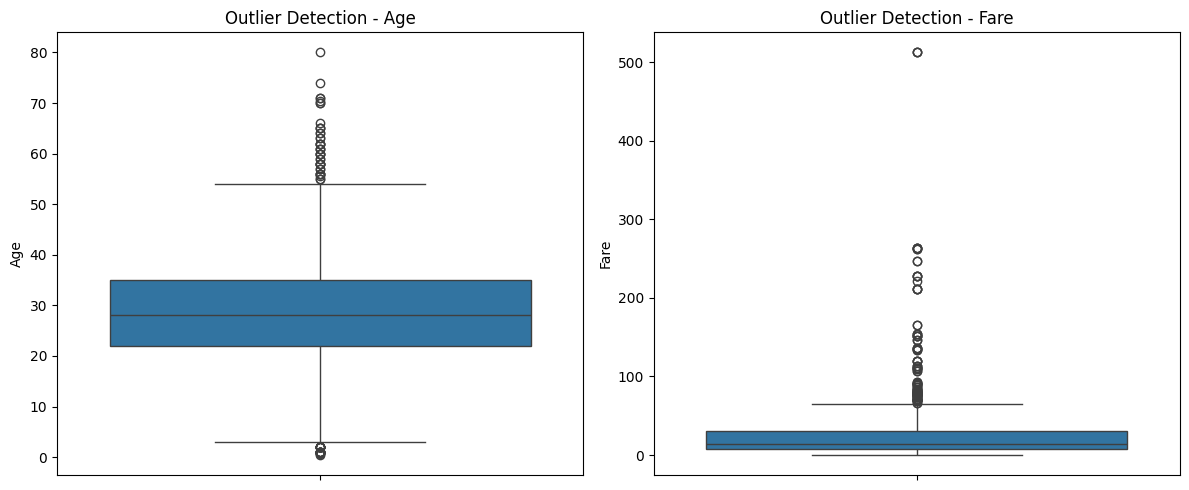

In [9]:

plt.figure(figsize=(12, 5))

for i, col in enumerate(outlier_columns, 1):
    plt.subplot(1, 2, i)

    sns.boxplot(y=df[col])

    plt.title(f'Outlier Detection - {col}')
    plt.ylabel(col)

plt.tight_layout()
plt.show()


In [10]:

# Convert numeric columns to appropriate data types

df['Age'] = pd.to_numeric(df['Age'], errors='coerce')
df['Fare'] = pd.to_numeric(df['Fare'], errors='coerce')

df['Pclass'] = df['Pclass'].astype('int64')
df['Survived'] = df['Survived'].astype('int64')

print("Updated Data Types:")
print(df.dtypes)

print("\nData type correction completed!")


Updated Data Types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object

Data type correction completed!


In [11]:

# Calculate before and after metrics

comparison = pd.DataFrame({
    'Metric': [
        'Total Rows',
        'Total Columns',
        'Missing Values',
        'Duplicate Rows'
    ],
    'Before Cleaning': [
        original_df.shape[0],
        original_df.shape[1],
        original_df.isnull().sum().sum(),
        original_df.duplicated().sum()
    ],
    'After Cleaning': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum()
    ]
})

display(comparison)


,Metric,Before Cleaning,After Cleaning
0,Total Rows,891,891
1,Total Columns,12,11
2,Missing Values,866,0
3,Duplicate Rows,0,0


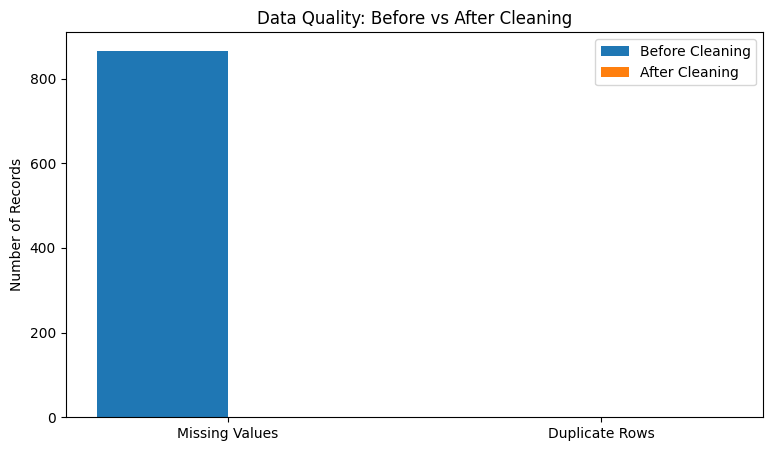

In [12]:

plt.figure(figsize=(9, 5))

comparison_metrics = ['Missing Values', 'Duplicate Rows']

before_values = [
    original_df.isnull().sum().sum(),
    original_df.duplicated().sum()
]

after_values = [
    df.isnull().sum().sum(),
    df.duplicated().sum()
]

x = np.arange(len(comparison_metrics))
width = 0.35

plt.bar(x - width/2, before_values, width, label='Before Cleaning')
plt.bar(x + width/2, after_values, width, label='After Cleaning')

plt.xticks(x, comparison_metrics)
plt.ylabel('Number of Records')
plt.title('Data Quality: Before vs After Cleaning')
plt.legend()
plt.show()


In [13]:

print("=" * 60)
print("       FINAL DATA CLEANING REPORT")
print("=" * 60)

print("\n1. DATASET INFORMATION")
print("-" * 40)
print("Original Dataset Shape:", original_df.shape)
print("Cleaned Dataset Shape :", df.shape)

print("\n2. MISSING VALUE ANALYSIS")
print("-" * 40)
print("Before Cleaning:", original_df.isnull().sum().sum())
print("After Cleaning :", df.isnull().sum().sum())

print("\n3. DUPLICATE ANALYSIS")
print("-" * 40)
print("Before Cleaning:", original_df.duplicated().sum())
print("After Cleaning :", df.duplicated().sum())

print("\n4. DATA TYPE VERIFICATION")
print("-" * 40)
print(df.dtypes)

print("\n5. OUTLIER ANALYSIS")
print("-" * 40)
display(pd.DataFrame(outlier_report))

print("\n6. CLEANING ACTIONS")
print("-" * 40)
print("""
- Filled missing Age values using the median.
- Filled missing Embarked values using the mode.
- Removed the Cabin column due to extensive missing data.
- Removed duplicate records.
- Standardised text formatting.
- Detected outliers using the IQR method.
- Retained legitimate outliers.
- Verified and corrected data types.
""")

print("=" * 60)
print("          REPORT COMPLETED")
print("=" * 60)


       FINAL DATA CLEANING REPORT

1. DATASET INFORMATION
----------------------------------------
Original Dataset Shape: (891, 12)
Cleaned Dataset Shape : (891, 11)

2. MISSING VALUE ANALYSIS
----------------------------------------
Before Cleaning: 866
After Cleaning : 0

3. DUPLICATE ANALYSIS
----------------------------------------
Before Cleaning: 0
After Cleaning : 0

4. DATA TYPE VERIFICATION
----------------------------------------
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Embarked        object
dtype: object

5. OUTLIER ANALYSIS
----------------------------------------


,Column,Lower Limit,Upper Limit,Outlier Count
0,Age,2.500,54.5000,66
1,Fare,-26.724,65.6344,116



6. CLEANING ACTIONS
----------------------------------------

- Filled missing Age values using the median.
- Filled missing Embarked values using the mode.
- Removed the Cabin column due to extensive missing data.
- Removed duplicate records.
- Standardised text formatting.
- Detected outliers using the IQR method.
- Retained legitimate outliers.
- Verified and corrected data types.

          REPORT COMPLETED


In [14]:

# Export cleaned dataset
df.to_csv('cleaned_titanic_dataset.csv', index=False)

print("Cleaned dataset exported successfully!")

# Download the cleaned dataset in Google Colab
from google.colab import files
files.download('cleaned_titanic_dataset.csv')


Cleaned dataset exported successfully!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>